# AirLab — ITS · полный анализ с нуля (FASTQ → итоговые результаты)

**Единый рабочий процесс:** FastQC/MultiQC → Cutadapt → DADA2 → ASV → RDP Naive Bayesian Classifier (UNITE, bootstrap ≥90) → BLASTN (UNITE) → согласование таксономии → `phyloseq` → разнообразие и статистика.

Ноутбук рассчитан на **первый запуск проекта ITS**. До начала выполнения каталога `results/ITS/` **нет**, и ни одна ячейка не читает из него данные. Все этапы заново используют исходные парные FASTQ и исходную базу UNITE. При запуске анализ создаёт **`results/ITS/`** и записывает итоговые файлы непосредственно туда. Промежуточные FASTQ, BLAST-база и технические журналы временно располагаются в скрытом подкаталоге `results/ITS/.work/` и удаляются после успешного выполнения. Если расчёт прервётся, `results/ITS/` может содержать неполные результаты; перед новым запуском её следует удалить вручную. Другие каталоги результатов не затрагиваются.

В результате будет **одна таблица таксономии для всех ASV** (`ITS_taxonomy_complete.tsv`): последовательности, таксоны и bootstrap RDP, лучшие и неоднозначные BLAST-попадания, итоговые таксономические ранги и причина назначения. Вид записывается в итоговую `Species` **только при совпадении видовых определений двух методов**. Названия родов RDP принимаются при bootstrap ≥90; BLAST-only назначения родов отдельно отмечаются как *предварительные*.

**Научная оговорка:** эта реализация воспроизводит принцип согласования RDP + BLASTN, описанный Rodó et al. (2024), но не означает точного совпадения баз и параметров авторов. Оба метода здесь используют UNITE 10.0, поэтому BLASTN не является независимой проверкой референсной базы. Отрицательные контроли и метеорологические данные не придумываются.

Источники: [Rodó et al., PNAS 2024](https://doi.org/10.1073/pnas.2404191121) · [репозиторий авторов](https://github.com/AirLabBcn/microbial-richness-troposphere) · [DADA2](https://benjjneb.github.io/dada2/) · [NCBI BLAST+](https://www.ncbi.nlm.nih.gov/books/NBK279690/).


## 1. Настройки и проверка входных данных

Запускай ячейки сверху вниз на **вычислительном узле** с R-ядром AirLab. Исходные FASTQ и UNITE должны быть на месте. **Никаких команд удаления старых результатов не требуется** — это первый запуск.

Численные пороги BLAST (99 % identity, 95 % покрытия, E-value ≤ 1e−20) — консервативные настройки **этого** анализа; они не заявляются как точные параметры оригинальной статьи или универсальные пороги видов грибов.


In [3]:
project_dir <- "/home/panishevasa/airlab/pipeline"
raw_dir <- "/home/panishevasa/airlab/test_16S_ITS_data"
env_bin <- "/home/panishevasa/airlab/envs/amplicon/bin"
marker <- "ITS"
primer_fwd <- "TAGAGGAAGTAAAAGTCGTAA"
primer_rev <- "TTYRCTRCGTTCTTCATC"
taxonomy_ref <- file.path(project_dir, "refdb/unite_v10.0/sh_general_release_dynamic_s_all_19.02.2025.fasta")
tax_levels <- c("Kingdom", "Phylum", "Class", "Order", "Family", "Genus", "Species")

run_fastqc <- TRUE
max_ee <- c(2, 2)
trunc_len <- c(0L, 0L)   # ITS имеет переменную длину: НЕ обрезаем до фиксированной длины
min_len <- 50L
min_reads <- 100L
min_boot <- 90L       # RDP bootstrap 90
pooling <- "pseudo"
min_overlap <- 12L
min_pilot_retention <- 0.50
blast_min_identity <- 99
blast_min_coverage <- 95
blast_max_evalue <- 1e-20
blast_near_best_bits <- 1
blast_max_hits <- 500L
set.seed(139)

if (!dir.exists(project_dir)) stop("Missing project directory: ", project_dir)
if (!dir.exists(raw_dir)) stop("Missing raw FASTQ directory: ", raw_dir)
if (grepl("^sms", Sys.info()[["nodename"]])) stop("Run on a SLURM compute node, not on sms")
Sys.setenv(PATH=paste(env_bin, Sys.getenv("PATH"), sep=.Platform$path.sep))
needed <- c("dada2", "ShortRead", "Biostrings", "phyloseq", "vegan", "ggplot2")
missing <- needed[!vapply(needed, requireNamespace, logical(1), quietly=TRUE)]
if (length(missing)) stop("Missing R packages: ", paste(missing, collapse=", "))
cli <- c("cutadapt", "blastn", "makeblastdb", if (run_fastqc) c("fastqc", "multiqc"))
not_found <- cli[!nzchar(Sys.which(cli))]
if (length(not_found)) stop("Missing commands on current compute node: ", paste(not_found, collapse=", "),
                            ". BLAST may exist on sms but not on cn nodes. Install it into amplicon environment if needed.")
if (!file.exists(taxonomy_ref)) stop("Missing UNITE reference: ", taxonomy_ref)

allocated <- suppressWarnings(as.integer(Sys.getenv("SLURM_CPUS_PER_TASK", "1")))
if (!is.finite(allocated) || allocated < 1L) allocated <- 1L
threads <- min(4L, allocated)

# ITS запускается с нуля. Результаты сразу попадают в results/ITS/.
# Временные FASTQ и BLAST-база живут только в results/ITS/.work/.
results_dir <- file.path(project_dir, "results")
final_dir <- file.path(results_dir, "ITS")
if (file.exists(final_dir)) {
  stop("Папка results/ITS/ уже существует: ", final_dir,
       ". Для нового полного запуска удали её вручную, если старые результаты больше не нужны.")
}
dir.create(final_dir, recursive=TRUE, showWarnings=FALSE)
if (!dir.exists(final_dir)) stop("Не удалось создать папку: ", final_dir)
outdir <- final_dir
workdir <- file.path(outdir, ".work")
dir.create(workdir, recursive=TRUE, showWarnings=FALSE)
if (!dir.exists(workdir)) stop("Не удалось создать временную папку: ", workdir)

run_cmd <- function(exe, arguments, log_file) {
  dir.create(dirname(log_file), recursive=TRUE, showWarnings=FALSE)
  tool <- unname(Sys.which(exe))
  if (!nzchar(tool)) stop("Command not found: ", exe)
  rc <- suppressWarnings(system2(tool, args=shQuote(as.character(arguments)),
                                 stdout=log_file, stderr=log_file))
  if (!identical(as.integer(rc), 0L)) {
    if (file.exists(log_file)) cat(tail(readLines(log_file, warn=FALSE), 25), sep="\n")
    stop(exe, " failed, exit status ", rc, ". Log: ", log_file)
  }
  invisible(rc)
}
write_matrix <- function(x, filename) {
  write.table(x, file.path(outdir, filename), sep="\t", quote=FALSE,
              col.names=NA, na="NA")
}
write_rows <- function(x, filename) {
  write.table(x, file.path(outdir, filename), sep="\t", quote=FALSE,
              row.names=FALSE, na="NA")
}
get_cutadapt_n <- function(log_lines, phrase) {
  hit <- grep(phrase, log_lines, value=TRUE, fixed=TRUE)
  if (!length(hit)) return(NA_real_)
  as.numeric(gsub(",", "", sub(".*:[[:space:]]*([0-9,]+).*", "\\1", hit[1])))
}

cat("ITS | CPUs:", threads, "| RDP minBoot:", min_boot,
    "\nOutput:", outdir, "\nTemporary files: results/ITS/.work (auto-removed on success)",
    "\nBLAST:", Sys.which("blastn"), "\nUNITE:", taxonomy_ref, "\n")


ITS | CPUs: 2 | RDP minBoot: 90 
Output: /home/panishevasa/airlab/pipeline/results/ITS 
Temporary files: results/ITS/.work (auto-removed on success) 
BLAST: /home/panishevasa/airlab/envs/amplicon/bin/blastn 
UNITE: /home/panishevasa/airlab/pipeline/refdb/unite_v10.0/sh_general_release_dynamic_s_all_19.02.2025.fasta 


## 2. Исходные FASTQ и метаданные

Проверяем полные парные FASTQ и соответствие образцов опубликованным метаданным PNAS. Файл `metadata/samples_pnas.tsv` используется, если присутствует; иначе — встроенная копия. **Никакие тестовые метеозначения не подставляются.**


In [4]:
all_files <- list.files(raw_dir, full.names=TRUE)
suffix_f <- paste0("_1_", marker, ".fastq.gz")
suffix_r <- paste0("_2_", marker, ".fastq.gz")
fn_f <- all_files[endsWith(basename(all_files), suffix_f)]
fn_r <- all_files[endsWith(basename(all_files), suffix_r)]
ids_f <- substr(basename(fn_f), 1L, nchar(basename(fn_f)) - nchar(suffix_f))
ids_r <- substr(basename(fn_r), 1L, nchar(basename(fn_r)) - nchar(suffix_r))
if (!length(ids_f) || anyDuplicated(ids_f) || anyDuplicated(ids_r) || !setequal(ids_f, ids_r)) {
  cat("Missing R2 for:", paste(setdiff(ids_f, ids_r), collapse=", "), "\n")
  cat("Missing R1 for:", paste(setdiff(ids_r, ids_f), collapse=", "), "\n")
  stop("Incomplete or duplicated R1/R2 pairs")
}
order_f <- order(ids_f)
fn_f <- fn_f[order_f]; sample_ids <- ids_f[order_f]
fn_r <- fn_r[match(sample_ids, ids_r)]
names(fn_f) <- names(fn_r) <- sample_ids
if (!all(file.info(c(fn_f, fn_r))$size > 0)) stop("Empty FASTQ files detected")
cat("Complete FASTQ pairs:", length(sample_ids), "\n")

metadata_embedded <- "sample_id\tis_control\tsite_id\tsite_type\tsampling_date\tdatetime_start\tdatetime_end\tsampling_timezone\taltitude_min_m\taltitude_max_m\tair_volume_m3\tdna_yield_ng_m3\tpublished_16S_success\tpublished_ITS_success\textraction_batch\tlibrary_batch\tseason\ttemp_c\trh_pct\twind_ms\tprecip_mm\tpressure_hpa\tpm25\tpm10\tmetadata_source\nS1\tFALSE\tNA\tFlight\t2014-02-22\t2014-02-22T12:10:00\t2014-02-22T15:00:00\tAsia/Tokyo\t1000\t3000\t83.6\t0.155\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS2\tFALSE\tNA\tGround\t2014-02-23\t2014-02-23T00:00:00\t2014-02-23T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.134\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS3\tFALSE\tNA\tFlight\t2014-02-23\t2014-02-23T12:04:00\t2014-02-23T14:50:00\tAsia/Tokyo\t1000\t3000\t83.7\t0.140\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS4\tFALSE\tNA\tGround\t2014-02-24\t2014-02-24T00:00:00\t2014-02-24T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.078\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS5\tFALSE\tNA\tFlight\t2014-02-24\t2014-02-24T12:04:00\t2014-02-24T14:38:00\tAsia/Tokyo\t1000\t3000\t84.0\t0.240\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS6\tFALSE\tNA\tGround\t2014-02-25\t2014-02-25T00:00:00\t2014-02-25T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.354\tYES\tNO\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS7\tFALSE\tNA\tFlight\t2014-02-25\t2014-02-25T12:18:00\t2014-02-25T15:00:00\tAsia/Tokyo\t1000\t3000\t88.4\t0.041\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS8\tFALSE\tNA\tGround\t2014-02-26\t2014-02-26T00:00:00\t2014-02-26T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.087\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS9\tFALSE\tNA\tFlight\t2014-02-26\t2014-02-26T12:24:00\t2014-02-26T15:10:00\tAsia/Tokyo\t1000\t3000\t82.6\t0.051\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS10\tFALSE\tNA\tGround\t2014-02-27\t2014-02-27T00:00:00\t2014-02-27T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.089\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS11\tFALSE\tNA\tGround\t2014-02-28\t2014-02-28T12:00:00\t2014-02-28T15:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.095\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS12\tFALSE\tNA\tGround\t2014-03-01\t2014-03-01T00:00:00\t2014-03-01T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.162\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS13\tFALSE\tNA\tFlight\t2014-04-01\t2014-04-01T12:10:00\t2014-04-01T14:58:00\tAsia/Tokyo\t1000\t3000\t81.3\t0.053\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS14\tFALSE\tNA\tGround\t2014-04-01\t2014-04-01T00:00:00\t2014-04-01T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.000\tNO\tNO\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS15\tFALSE\tNA\tFlight\t2014-04-05\t2014-04-05T11:50:00\t2014-04-05T14:35:00\tAsia/Tokyo\t1000\t3000\t83.9\t0.035\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS16\tFALSE\tNA\tGround\t2014-04-06\t2014-04-06T00:00:00\t2014-04-06T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.066\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS17\tFALSE\tNA\tFlight\t2014-04-06\t2014-04-06T10:47:00\t2014-04-06T13:11:00\tAsia/Tokyo\t1000\t3000\t72.9\t0.072\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS18\tFALSE\tNA\tGround\t2014-04-07\t2014-04-07T00:00:00\t2014-04-07T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.004\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS19\tFALSE\tNA\tFlight\t2014-04-07\t2014-04-07T12:15:00\t2014-04-07T14:55:00\tAsia/Tokyo\t1000\t3000\t79.7\t0.047\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS20\tFALSE\tNA\tGround\t2014-04-08\t2014-04-08T00:00:00\t2014-04-08T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.031\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS21\tFALSE\tNA\tFlight\t2014-04-08\t2014-04-08T12:15:00\t2014-04-08T14:53:00\tAsia/Tokyo\t1000\t3000\t79.0\t0.063\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS22\tFALSE\tNA\tGround\t2014-04-09\t2014-04-09T00:00:00\t2014-04-09T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.019\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1"
metadata_path <- file.path(project_dir, "metadata", "samples_pnas.tsv")
if (file.exists(metadata_path)) {
  published <- read.delim(metadata_path, sep="\t", na.strings="NA",
                          stringsAsFactors=FALSE, check.names=FALSE,
                          fileEncoding="UTF-8")
  cat("Metadata source:", metadata_path, "\n")
} else {
  published <- read.delim(text=metadata_embedded, sep="\t", na.strings="NA",
                          stringsAsFactors=FALSE, check.names=FALSE)
  cat("Metadata source: embedded PNAS supplementary table\n")
}
if (!"sample_id" %in% names(published) || anyDuplicated(published$sample_id))
  stop("Invalid sample_id in metadata")
if (!all(sample_ids %in% published$sample_id))
  stop("Metadata missing FASTQ IDs: ", paste(setdiff(sample_ids, published$sample_id), collapse=", "))
meta <- published[match(sample_ids, published$sample_id), , drop=FALSE]
rownames(meta) <- sample_ids
stopifnot(identical(meta$sample_id, sample_ids))


con <- if (grepl("\\.gz$", taxonomy_ref)) gzfile(taxonomy_ref, "rt") else file(taxonomy_ref, "rt")
ref_header <- readLines(con, n=1L, warn=FALSE); close(con)
if (!length(ref_header) || !startsWith(ref_header, ">")) stop("Reference file does not start with a FASTA header")
cat("Reference header:", substr(ref_header, 1, 180), "\n")
cat("Published records:", nrow(published), "| matched:", nrow(meta), "\n")
print(meta[, intersect(c("sample_id", "site_type", "sampling_date", "air_volume_m3",
                        "published_16S_success", "published_ITS_success"), names(meta)), drop=FALSE])


Complete FASTQ pairs: 20 
Metadata source: /home/panishevasa/airlab/pipeline/metadata/samples_pnas.tsv 
Reference header: >Ciliophora_sp|UDB02393310|SH0000001.10FU|reps_singleton|k__Alveolata;p__Ciliophora;c__Ciliophora_cls_Incertae_sedis;o__Ciliophora_ord_Incertae_sedis;f__Ciliophora_fam_Incertae_sed 
Published records: 22 | matched: 20 
    sample_id site_type sampling_date air_volume_m3 published_16S_success
S1         S1    Flight    2014-02-22          83.6                   YES
S10       S10    Ground    2014-02-27          90.0                   YES
S11       S11    Ground    2014-02-28          90.0                   YES
S12       S12    Ground    2014-03-01          90.0                   YES
S13       S13    Flight    2014-04-01          81.3                   YES
S15       S15    Flight    2014-04-05          83.9                   YES
S16       S16    Ground    2014-04-06          90.0                   YES
S17       S17    Flight    2014-04-06          72.9                

## 3. Контроль качества FASTQ

Кривые качества выводятся в ноутбук. FastQC и MultiQC формируются во временном рабочем каталоге; в результате сохраняется только **один итоговый HTML MultiQC**.


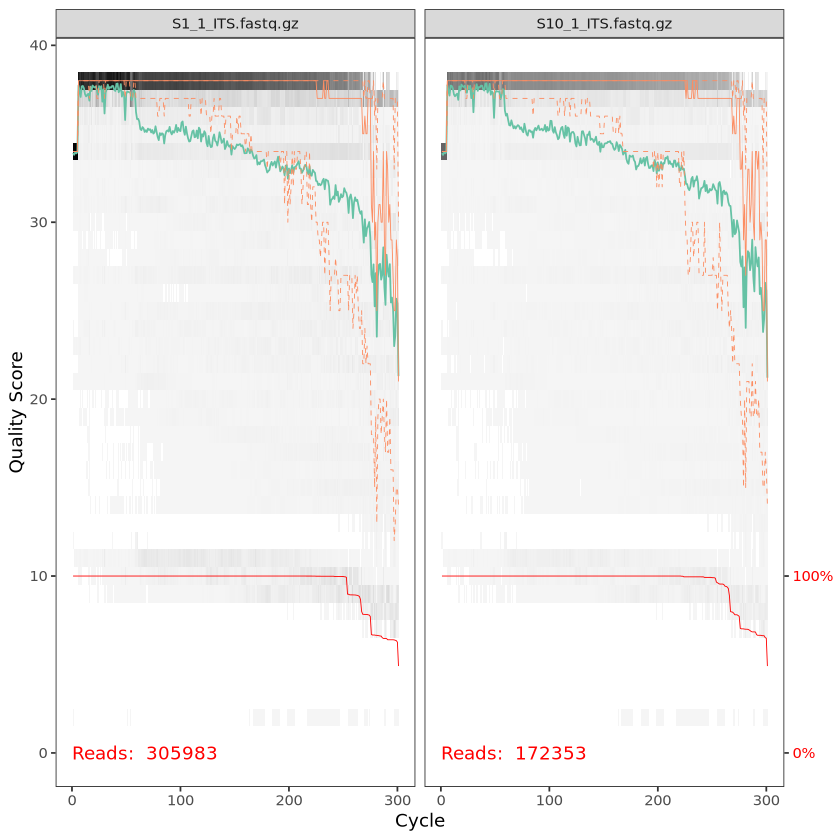

MultiQC: /home/panishevasa/airlab/pipeline/results/ITS/.work/multiqc/multiqc_report.html 


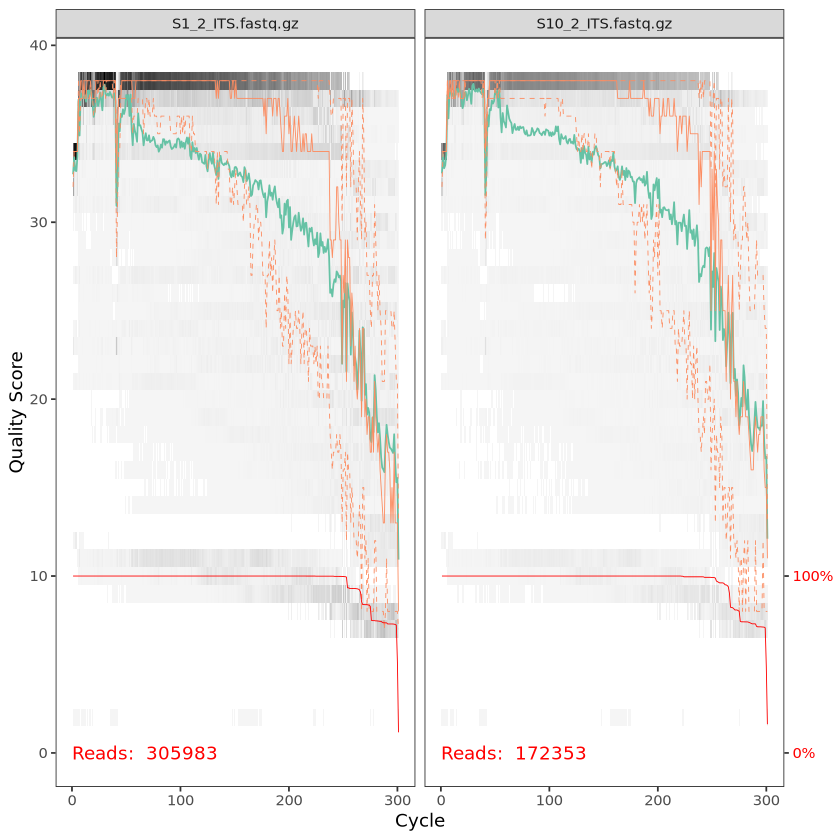

In [5]:
preview_ids <- head(sample_ids, 2L)
print(dada2::plotQualityProfile(unname(fn_f[preview_ids])))
print(dada2::plotQualityProfile(unname(fn_r[preview_ids])))
if (run_fastqc) {
  qcdir <- file.path(workdir, "fastqc")
  mqdir <- file.path(workdir, "multiqc")
  dir.create(qcdir, recursive=TRUE, showWarnings=FALSE)
  dir.create(mqdir, recursive=TRUE, showWarnings=FALSE)
  run_cmd("fastqc", c("-t", threads, "--outdir", qcdir, unname(fn_f), unname(fn_r)),
          file.path(workdir, "fastqc.log"))
  run_cmd("multiqc", c("--force", "--outdir", mqdir, qcdir),
          file.path(workdir, "multiqc.log"))
  cat("MultiQC:", file.path(mqdir, "multiqc_report.html"), "\n")
}


In [6]:
file.copy(
  file.path(workdir, "multiqc", "multiqc_report.html"),
  file.path(outdir, "ITS_MultiQC.html"),
  overwrite = TRUE
)

[1] TRUE

## 4. Проверка ориентации праймеров

Оцениваем праймеры на пробных чтениях и останавливаем анализ при вероятной путанице R1/R2.


In [7]:
primer_hits <- function(path, primer, n=500L) {
  stream <- ShortRead::FastqStreamer(path, n=n)
  on.exit(close(stream))
  fq <- ShortRead::yield(stream)
  if (!length(fq)) return(0L)
  s <- ShortRead::sread(fq)
  s <- s[Biostrings::width(s) >= nchar(primer)]
  if (!length(s)) return(0L)
  st <- Biostrings::subseq(s, start=1L, width=nchar(primer))
  sum(Biostrings::vcountPattern(primer, st, fixed=FALSE) > 0)
}
orientation <- data.frame(sample_id=sample_ids,
  expected_hits=vapply(seq_along(sample_ids), function(i)
    primer_hits(fn_f[i], primer_fwd) + primer_hits(fn_r[i], primer_rev), numeric(1)),
  swapped_hits=vapply(seq_along(sample_ids), function(i)
    primer_hits(fn_f[i], primer_rev) + primer_hits(fn_r[i], primer_fwd), numeric(1)))

print(orientation, row.names=FALSE)
if (any(orientation$swapped_hits >= 10 & orientation$swapped_hits > orientation$expected_hits))
  stop("Possible R1/R2 swap: inspect the printed primer check before Cutadapt")


 sample_id expected_hits swapped_hits
        S1           957            0
       S10           971            0
       S11           963            0
       S12           957            0
       S13           955            0
       S15           970            0
       S16           981            0
       S17           961            0
       S18           964            0
       S19           959            0
        S2           978            0
       S20           966            0
       S21           977            0
       S22           960            0
        S3           966            0
        S4           959            0
        S5           964            0
        S7           959            0
        S8           956            0
        S9           965            0


## 5. Cutadapt — удаление праймеров

Парная фильтрация и пробный контроль сохранения прочтений. Промежуточные FASTQ и логи временные. Результаты учёта чтений будут объединены в одну итоговую `ITS_read_tracking.tsv`.


In [8]:
trimdir <- file.path(workdir, "trimmed")
logdir <- file.path(workdir, "logs")
dir.create(trimdir, recursive=TRUE, showWarnings=FALSE)
dir.create(logdir, recursive=TRUE, showWarnings=FALSE)
trim_f <- setNames(file.path(trimdir, paste0(sample_ids, "_R1.fastq.gz")), sample_ids)
trim_r <- setNames(file.path(trimdir, paste0(sample_ids, "_R2.fastq.gz")), sample_ids)
rc_primer <- function(s) as.character(Biostrings::reverseComplement(Biostrings::DNAString(s)))
linked_f <- paste0("^", primer_fwd, "...", rc_primer(primer_rev))
linked_r <- paste0("^", primer_rev, "...", rc_primer(primer_fwd))
cut_args <- function(i) c("-a", linked_f, "-A", linked_r,
                           "--discard-untrimmed", "--pair-filter=any",
                           "--minimum-length", min_len, "-j", threads,
                           "-o", trim_f[i], "-p", trim_r[i], fn_f[i], fn_r[i])
cut_log <- function(id) file.path(logdir, paste0(id, ".cutadapt.log"))

cat("Pilot Cutadapt sample:", sample_ids[1], "\n")
run_cmd("cutadapt", cut_args(1), cut_log(sample_ids[1]))
pilot_text <- readLines(cut_log(sample_ids[1]), warn=FALSE)
cat(grep("Total read pairs processed|Read 1 with adapter|Read 2 with adapter|Pairs written|Pairs discarded",
         pilot_text, value=TRUE), sep="\n")
pilot_in <- get_cutadapt_n(pilot_text, "Total read pairs processed:")
pilot_out <- get_cutadapt_n(pilot_text, "Pairs written (passing filters):")
if (!is.finite(pilot_in) || !is.finite(pilot_out) || pilot_in == 0 ||
    pilot_out / pilot_in < min_pilot_retention)
  stop("Cutadapt pilot retained too few reads: inspect primers and pilot log")
cat("Pilot retained:", round(100*pilot_out/pilot_in, 2), "%\n")

for (i in seq_along(sample_ids)[-1L]) {
  cat("Cutadapt:", i, "/", length(sample_ids), sample_ids[i], "\n")
  run_cmd("cutadapt", cut_args(i), cut_log(sample_ids[i]))
}
cut_qc <- do.call(rbind, lapply(sample_ids, function(id) {
  x <- readLines(cut_log(id), warn=FALSE)
  before <- get_cutadapt_n(x, "Total read pairs processed:")
  after <- get_cutadapt_n(x, "Pairs written (passing filters):")
  data.frame(sample_id=id, raw_pairs=before, trimmed_pairs=after,
             retained_pct=round(100*after/before, 2))
}))
if (any(!is.finite(cut_qc$retained_pct))) stop("Some Cutadapt summary logs are incomplete")

print(cut_qc, row.names=FALSE)
cat("Median Cutadapt retention:", median(cut_qc$retained_pct), "%\n")


Pilot Cutadapt sample: S1 
Total read pairs processed:            305,983
  Read 1 with adapter:                 305,546 (99.9%)
  Read 2 with adapter:                 303,064 (99.0%)
Pairs discarded as untrimmed:            3,317 (1.1%)
Pairs written (passing filters):       302,666 (98.9%)
Pilot retained: 98.92 %
Cutadapt: 2 / 20 S10 
Cutadapt: 3 / 20 S11 
Cutadapt: 4 / 20 S12 
Cutadapt: 5 / 20 S13 
Cutadapt: 6 / 20 S15 
Cutadapt: 7 / 20 S16 
Cutadapt: 8 / 20 S17 
Cutadapt: 9 / 20 S18 
Cutadapt: 10 / 20 S19 
Cutadapt: 11 / 20 S2 
Cutadapt: 12 / 20 S20 
Cutadapt: 13 / 20 S21 
Cutadapt: 14 / 20 S22 
Cutadapt: 15 / 20 S3 
Cutadapt: 16 / 20 S4 
Cutadapt: 17 / 20 S5 
Cutadapt: 18 / 20 S7 
Cutadapt: 19 / 20 S8 
Cutadapt: 20 / 20 S9 
 sample_id raw_pairs trimmed_pairs retained_pct
        S1    305983        302666        98.92
       S10    172353        170779        99.09
       S11    123075        121955        99.09
       S12     94185         93319        99.08
       S13     83150 

## 6. DADA2 — фильтрация чтений

Для ITS `truncLen = c(0, 0)`, чтобы не навязывать ампликонам фиксированную длину.


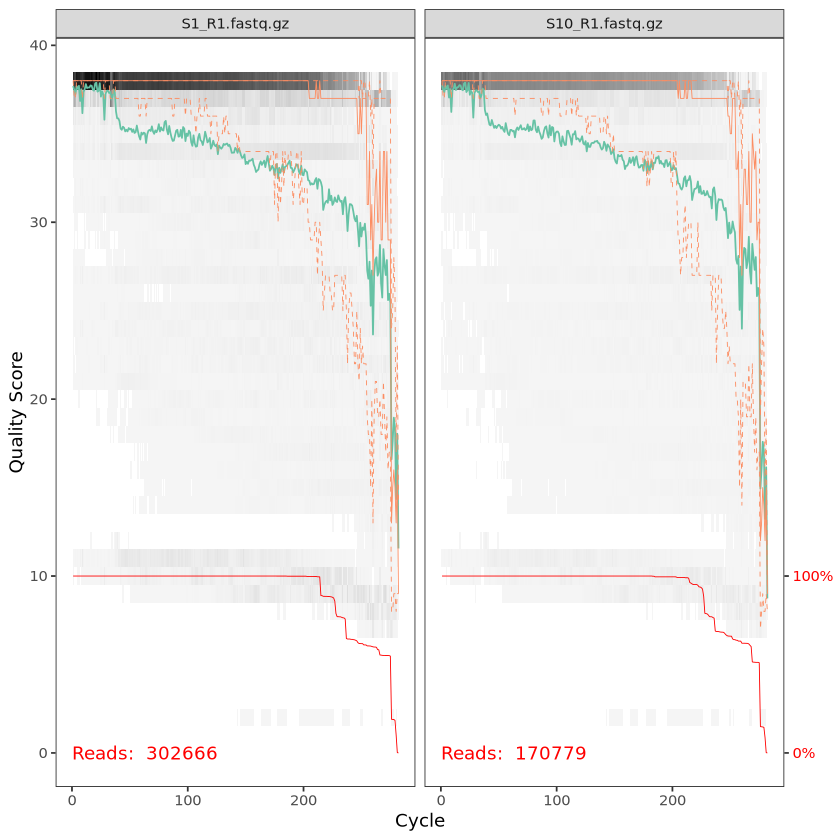

    reads.in reads.out
S1    302666    158183
S10   170779     94668
S11   121955     73865
S12    93319     53346
S13    82275     43543
S15   254594    140478
S16   134778     68096
S17    69721     37583
S18    98699     54595
S19   121338     60916
S2    301291    166190
S20   170876     83095
S21   221791    115922
S22   245738    118014
S3    451772    268566
S4    188248    100098
S5    198542    104404
S7    180579     98903
S8    158566     76015
S9    103593     58539
Retained after quality filtering: 53.8 % | samples: 20 / 20 


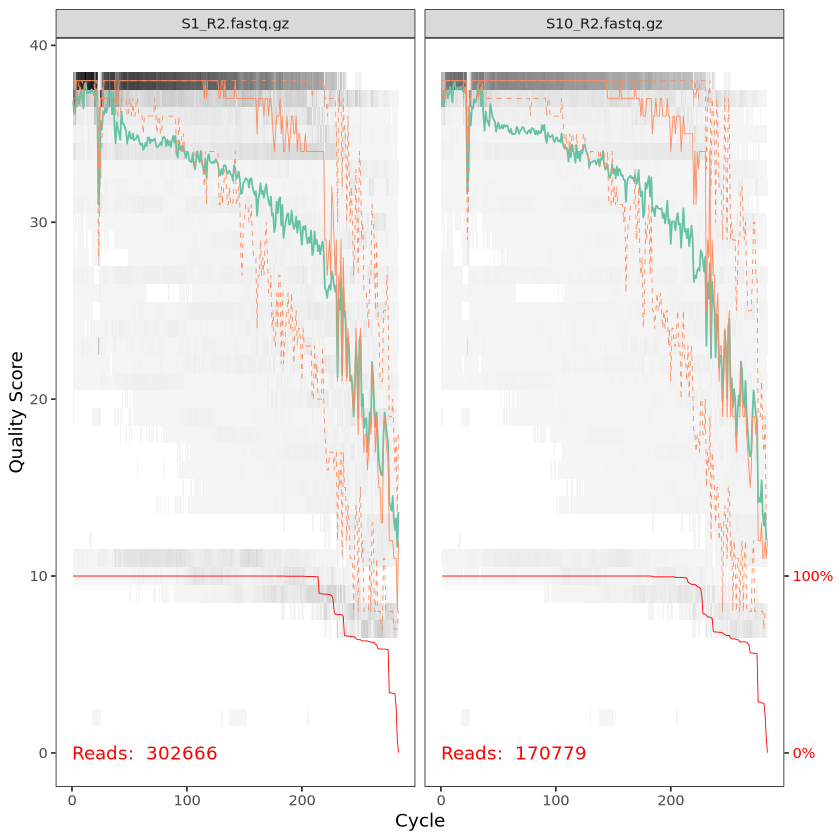

In [9]:
print(dada2::plotQualityProfile(unname(trim_f[preview_ids])))
print(dada2::plotQualityProfile(unname(trim_r[preview_ids])))
filtered_dir <- file.path(workdir, "filtered")
dir.create(filtered_dir, recursive=TRUE, showWarnings=FALSE)
filt_f <- setNames(file.path(filtered_dir, paste0(sample_ids, "_R1.fastq.gz")), sample_ids)
filt_r <- setNames(file.path(filtered_dir, paste0(sample_ids, "_R2.fastq.gz")), sample_ids)
filter_stats <- dada2::filterAndTrim(unname(trim_f), unname(filt_f),
  unname(trim_r), unname(filt_r), truncLen=trunc_len,
  maxN=0, maxEE=max_ee, truncQ=2, minLen=min_len, rm.phix=TRUE,
  compress=TRUE, multithread=threads, verbose=TRUE)
rownames(filter_stats) <- sample_ids
keep <- filter_stats[, "reads.out"] >= min_reads
kept_ids <- sample_ids[keep]
if (!length(kept_ids)) stop("No samples passed DADA2 filter")


print(filter_stats)
cat("Retained after quality filtering:",
    round(100 * sum(filter_stats[,"reads.out"]) / sum(filter_stats[,"reads.in"]), 1),
    "% | samples:", length(kept_ids), "/", length(sample_ids), "\n")


## 7. DADA2 — модель ошибок и денойзинг

Ошибки обучаются по очищенным данным, затем выполняются дерепликация и DADA2 pseudo-pooling.


106486786 total bases in 423605 reads from 5 samples will be used for learning the error rates.
106627890 total bases in 423605 reads from 5 samples will be used for learning the error rates.


Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”
Warning message:
“Removed 164 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 164 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 164 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 164 rows containing missing values or values outside the scale range (`geom_line()`).”


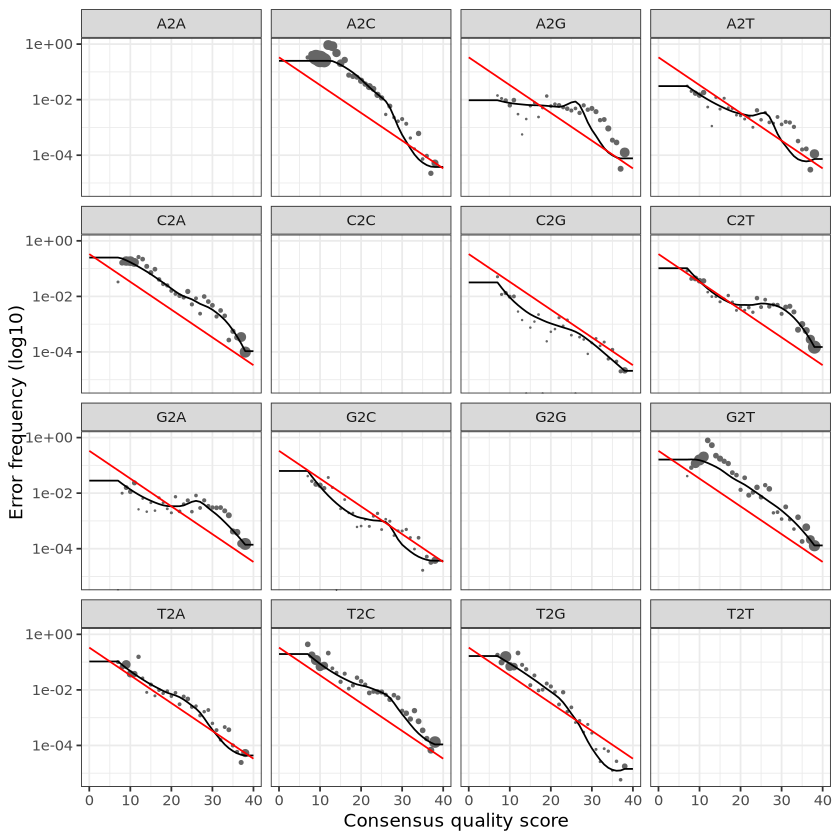

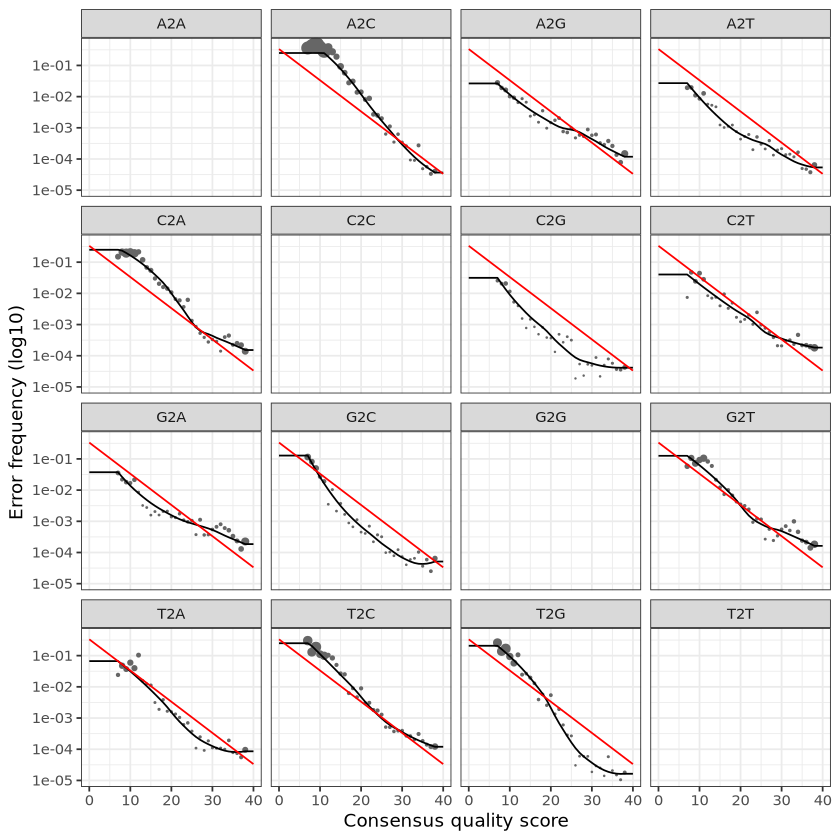

In [10]:
err_f <- dada2::learnErrors(unname(filt_f[kept_ids]), multithread=threads)
err_r <- dada2::learnErrors(unname(filt_r[kept_ids]), multithread=threads)

print(dada2::plotErrors(err_f, nominalQ=TRUE))
print(dada2::plotErrors(err_r, nominalQ=TRUE))


In [11]:
derep_f <- dada2::derepFastq(unname(filt_f[kept_ids]), verbose=FALSE)
derep_r <- dada2::derepFastq(unname(filt_r[kept_ids]), verbose=FALSE)
names(derep_f) <- names(derep_r) <- kept_ids
dada_f <- dada2::dada(derep_f, err=err_f, pool=pooling, multithread=threads)
dada_r <- dada2::dada(derep_r, err=err_r, pool=pooling, multithread=threads)
stopifnot(identical(names(dada_f), kept_ids), identical(names(dada_r), kept_ids))

cat("Denoised samples:", length(dada_f), "\n")


Sample 1 - 158183 reads in 12340 unique sequences.
Sample 2 - 94668 reads in 8296 unique sequences.
Sample 3 - 73865 reads in 7908 unique sequences.
Sample 4 - 53346 reads in 5568 unique sequences.
Sample 5 - 43543 reads in 4165 unique sequences.
Sample 6 - 140478 reads in 8641 unique sequences.
Sample 7 - 68096 reads in 4782 unique sequences.
Sample 8 - 37583 reads in 3236 unique sequences.
Sample 9 - 54595 reads in 5608 unique sequences.
Sample 10 - 60916 reads in 4492 unique sequences.
Sample 11 - 166190 reads in 16282 unique sequences.
Sample 12 - 83095 reads in 7259 unique sequences.
Sample 13 - 115922 reads in 8063 unique sequences.
Sample 14 - 118014 reads in 7392 unique sequences.
Sample 15 - 268566 reads in 28508 unique sequences.
Sample 16 - 100098 reads in 7560 unique sequences.
Sample 17 - 104404 reads in 7672 unique sequences.
Sample 18 - 98903 reads in 7471 unique sequences.
Sample 19 - 76015 reads in 9769 unique sequences.
Sample 20 - 58539 reads in 5452 unique sequences

## 8. DADA2 — слияние пар, удаление химер и ASV

Здесь формируется единая матрица нехимерных ASV. Промежуточные RDS не записываются.


In [12]:
mergers <- dada2::mergePairs(dada_f, derep_f, dada_r, derep_r,
                            minOverlap=min_overlap, maxMismatch=0, verbose=TRUE)
merge_counts <- vapply(mergers, function(z) sum(dada2::getUniques(z)), numeric(1))
merge_in <- pmin(vapply(dada_f, function(z) sum(dada2::getUniques(z)), numeric(1)),
                 vapply(dada_r, function(z) sum(dada2::getUniques(z)), numeric(1)))
merge_rate <- merge_counts / pmax(merge_in, 1)
merge_qc <- data.frame(sample_id=names(merge_counts), pairs_considered=merge_in,
                       merged=merge_counts, merged_pct=round(100*merge_rate, 2))

print(merge_qc, row.names=FALSE)
if (any(merge_rate < 0.5)) warning("Some samples have <50% merge success. Check ITS amplicon length/primers/quality")

seqtab_before_chimera <- dada2::makeSequenceTable(mergers)
seqtab_nochim <- dada2::removeBimeraDenovo(
  seqtab_before_chimera, method="consensus", multithread=threads)
if (!ncol(seqtab_nochim) || sum(seqtab_nochim)==0) stop("No non-chimeric ASVs remain")


cat("ASVs before chimera removal:", ncol(seqtab_before_chimera),
    "| after:", ncol(seqtab_nochim),
    "| non-chimeric reads:", sum(seqtab_nochim), "\n")


155948 paired-reads (in 163 unique pairings) successfully merged out of 158041 (in 270 pairings) input.

94341 paired-reads (in 73 unique pairings) successfully merged out of 94646 (in 88 pairings) input.

73496 paired-reads (in 169 unique pairings) successfully merged out of 73838 (in 193 pairings) input.

52597 paired-reads (in 154 unique pairings) successfully merged out of 53255 (in 200 pairings) input.

42564 paired-reads (in 97 unique pairings) successfully merged out of 43519 (in 162 pairings) input.

138234 paired-reads (in 26 unique pairings) successfully merged out of 140203 (in 66 pairings) input.

65913 paired-reads (in 51 unique pairings) successfully merged out of 68087 (in 129 pairings) input.

37080 paired-reads (in 53 unique pairings) successfully merged out of 37574 (in 108 pairings) input.

54260 paired-reads (in 37 unique pairings) successfully merged out of 54541 (in 66 pairings) input.

59520 paired-reads (in 78 unique pairings) successfully merged out of 60648 (i

 sample_id pairs_considered merged merged_pct
        S1           158075 155948      98.65
       S10            94649  94341      99.67
       S11            73847  73496      99.52
       S12            53270  52597      98.74
       S13            43521  42564      97.80
       S15           140318 138234      98.51
       S16            68088  65913      96.81
       S17            37576  37080      98.68
       S18            54546  54260      99.48
       S19            60672  59520      98.10
        S2           165952 160703      96.84
       S20            83008  80986      97.56
       S21           115810 111697      96.45
       S22           117904 116184      98.54
        S3           268174 263521      98.26
        S4            99925  97386      97.46
        S5           104297 101297      97.12
        S7            98769  97953      99.17
        S8            75988  75196      98.96
        S9            58529  57641      98.48
ASVs before chimera removal: 1140 

## 9. Единая таксономия: RDP Naive Bayesian Classifier (bootstrap ≥90)

**Один вызов `dada2::assignTaxonomy()` с `outputBootstraps=TRUE`.** Обрабатываются **все нехимерные ASV**, включая те, которые не удалось уверенно отнести к грибам. Результаты RDP и bootstrap до конца анализа остаются в памяти и позже войдут **в одну общую таблицу**.


In [13]:
sequences <- colnames(seqtab_nochim)
asv_ids <- sprintf("ASV%06d", seq_along(sequences))
seq_map <- setNames(sequences, asv_ids)
seqtab <- seqtab_nochim
colnames(seqtab) <- asv_ids

rdp_result <- dada2::assignTaxonomy(
  sequences, taxonomy_ref, minBoot=min_boot,
  taxLevels=tax_levels, tryRC=TRUE,
  multithread=threads, outputBootstraps=TRUE
)

UNITE fungal taxonomic reference detected.


In [14]:
rdp_tax <- rdp_result$tax
rdp_boot <- rdp_result$boot
rownames(rdp_tax) <- rownames(rdp_boot) <- asv_ids
stopifnot(identical(colnames(seqtab),rownames(rdp_tax)),
          identical(colnames(rdp_tax),tax_levels),
          identical(dim(rdp_tax),dim(rdp_boot)))
cat("RDP90 taxonomy completed:", nrow(rdp_tax), "ASVs.\n")
print(head(rdp_tax, 4))

RDP90 taxonomy completed: 1105 ASVs.
          Kingdom    Phylum          Class                Order              
ASV000001 "k__Fungi" "p__Ascomycota" NA                   NA                 
ASV000002 NA         NA              NA                   NA                 
ASV000003 "k__Fungi" "p__Ascomycota" "c__Dothideomycetes" "o__Cladosporiales"
ASV000004 "k__Fungi" NA              NA                   NA                 
          Family               Genus             Species             
ASV000001 NA                   NA                NA                  
ASV000002 NA                   NA                NA                  
ASV000003 "f__Cladosporiaceae" "g__Cladosporium" "s__cladosporioides"
ASV000004 NA                   NA                NA                  


## 10. BLASTN по UNITE — построение временной базы

Референсный FASTA UNITE сохраняется в **рабочем**, а не в итоговом каталоге. Временной BLAST-базе присваиваются короткие уникальные ID, связанные со всеми таксономическими рангами, чтобы избежать ошибок разбора заголовков.


In [15]:
unite_lineage <- function(header) {
  parts <- strsplit(header, "|", fixed=TRUE)[[1]]
  possible <- parts[grepl("(^|;)k__", parts)]
  if (length(possible)) return(trimws(possible[length(possible)]))
  if (grepl("(^|;)k__", header)) return(trimws(header))
  NA_character_
}
rank_from_unite <- function(lineage, prefix) {
  if (is.na(lineage)) return(NA_character_)
  parts <- trimws(strsplit(lineage, ";", fixed=TRUE)[[1]])
  rank <- parts[startsWith(parts, paste0(prefix,"__"))]
  if (!length(rank) || !nzchar(substring(rank[1],4L))) return(NA_character_)
  rank[1]
}
plain_name <- function(x, prefix) {
  if (is.na(x) || !nzchar(x)) return(NA_character_)
  trimws(sub(paste0("^",prefix,"__"),"",x))
}
canonical_species <- function(genus, species) {
  if (is.na(genus) || is.na(species)) return(NA_character_)
  g <- plain_name(genus,"g")
  s <- gsub("_", " ", plain_name(species,"s"))
  if (!grepl("^[A-Z][A-Za-z-]+$", g) ||
      grepl("uncultured|unidentified|unknown|environmental|incertae|metagenom", s,
            ignore.case=TRUE)) return(NA_character_)
  if (startsWith(s, paste0(g," "))) s <- substring(s,nchar(g)+2L)
  if (!grepl("^[a-z][a-z0-9.-]+$", s) ||
      s %in% c("sp", "cf", "aff", "spp")) return(NA_character_)
  paste(g,s)
}

ref_sequences <- Biostrings::readDNAStringSet(taxonomy_ref)
ref_lineage <- vapply(names(ref_sequences), unite_lineage, character(1))
if (!length(ref_lineage) || mean(!is.na(ref_lineage)) < 0.90) {
  stop("UNITE headers could not be parsed. Check format of taxonomy_ref.")
}
ref_ids <- sprintf("REF%07d", seq_along(ref_sequences))
ref_map <- data.frame(REF=ref_ids, stringsAsFactors=FALSE)
rank_prefix <- c(Kingdom="k", Phylum="p", Class="c", Order="o",
                 Family="f", Genus="g", Species="s")
for (rank in tax_levels) {
  ref_map[[rank]] <- vapply(ref_lineage, rank_from_unite, character(1),
                            prefix=rank_prefix[[rank]])
}
ref_map$Binomial <- mapply(canonical_species, ref_map$Genus,
                          ref_map$Species, USE.NAMES=FALSE)
ref_query <- Biostrings::DNAStringSet(unname(seq_map))
names(ref_query) <- asv_ids
query_fasta <- file.path(workdir,"ITS_ASVs.fasta")
Biostrings::writeXStringSet(ref_query, query_fasta)
names(ref_sequences) <- paste0("lcl|",ref_ids)
ref_fasta <- file.path(workdir,"UNITE_BLAST_reference.fasta")
Biostrings::writeXStringSet(ref_sequences,ref_fasta)
rm(ref_sequences,ref_lineage,ref_query)
invisible(gc())

blast_db <- file.path(workdir,"UNITE_blastdb")
run_cmd("makeblastdb",
  c("-in",ref_fasta,"-dbtype","nucl","-parse_seqids","-out",blast_db),
  file.path(workdir,"makeblastdb.log"))
cat("BLAST database prepared; mapped reference records:",nrow(ref_map),"\n")


BLAST database prepared; mapped reference records: 266589 


## 11. BLASTN — все ASV и проверка неоднозначных попаданий

Сохраняем до 500 совпадений на ASV и анализируем все результаты, близкие к лучшему битовому счёту. **Вид нельзя принять, если лучшие совпадения указывают на разные виды**, низкого качества или обрезаны лимитом выдачи. Все подробности (включая альтернативные таксоны) попадут в единую таксономическую таблицу.


In [16]:
blast_tsv <- file.path(workdir,"blast_hits.tsv")
blast_outfmt <- "6 qseqid sseqid pident qcovhsp evalue bitscore length qlen"
run_cmd("blastn",
  c("-query",query_fasta,"-db",blast_db,"-task","blastn",
    "-dust","no","-evalue","1e-10","-max_target_seqs",blast_max_hits,
    "-max_hsps","1","-num_threads",threads,
    "-outfmt",blast_outfmt,"-out",blast_tsv),
  file.path(workdir,"blastn.log"))

hit_names <- c("ASV","Subject","Identity","Coverage","Evalue","BitScore","AlignLen","QueryLen")
if (file.size(blast_tsv) > 0L) {
  blast_hits <- read.delim(blast_tsv,header=FALSE,sep="\t",
    col.names=hit_names,stringsAsFactors=FALSE)
} else {
  blast_hits <- as.data.frame(setNames(replicate(length(hit_names),character(),
    simplify=FALSE), hit_names), stringsAsFactors=FALSE)
}
blast_hits$REF <- sub("^lcl\\|", "", blast_hits$Subject)
ref_match <- match(blast_hits$REF,ref_map$REF)
if (nrow(blast_hits) && anyNA(ref_match)) {
  stop("Some BLAST subject IDs do not match UNITE mapping. First missing: ",
       blast_hits$Subject[which(is.na(ref_match))[1]])
}
for (rank in tax_levels) blast_hits[[rank]] <- ref_map[[rank]][ref_match]
blast_hits$Binomial <- ref_map$Binomial[ref_match]

cat("BLASTN finished. Reported hits:",nrow(blast_hits),
    "| ASVs with hits:",length(unique(blast_hits$ASV)),"\n")


BLASTN finished. Reported hits: 516219 | ASVs with hits: 1102 


## 12. Согласование таксономии RDP × BLASTN

Финальная таксономия по всем ASV — только здесь. В колонках `Kingdom ... Species` хранится **итог**, `RDP_*` / `RDP_boot_*` — самостоятельные выводы классификатора, `BLAST_*` — однозначные высококачественные назначения, а в `Species_decision` и `Genus_source` записано основание решения. Вид появляется в `Species` только при **совпадении RDP90 и BLASTN**.

Однозначный род BLASTN при пропущенном роде RDP может использоваться лишь как **предварительное** определение, если оба метода согласны по семейству; это явно отмечено, а не выдаётся за видовое подтверждение.


In [17]:
# Выбираем таксоны только если все близкие к лучшему совпадения указывают
# на один и тот же ранг и удовлетворяют заданным порогам качества.
empty_blast <- as.list(setNames(rep(NA_character_,length(tax_levels)),tax_levels))
blast_summary_one <- function(h) {
  ans <- c(empty_blast, list(
    Best_subject=NA_character_, Best_identity=NA_real_, Best_coverage=NA_real_,
    Best_evalue=NA_real_, Best_bitscore=NA_real_, N_hits=0L, N_nearbest=0L,
    Nearbest_species=NA_character_, Binomial=NA_character_,
    Capped=FALSE, Status="no_hit"))
  if (!nrow(h)) return(ans)
  h <- h[order(-h$BitScore,-h$Identity,-h$Coverage,h$Subject),,drop=FALSE]
  top <- h[h$BitScore >= h$BitScore[1] - blast_near_best_bits,,drop=FALSE]
  quality_ok <- all(top$Identity >= blast_min_identity &
                    top$Coverage >= blast_min_coverage &
                    top$Evalue <= blast_max_evalue)
  capped <- nrow(h) >= blast_max_hits
  ans$Best_subject <- as.character(h$Subject[1])
  ans$Best_identity <- as.numeric(h$Identity[1])
  ans$Best_coverage <- as.numeric(h$Coverage[1])
  ans$Best_evalue <- as.numeric(h$Evalue[1])
  ans$Best_bitscore <- as.numeric(h$BitScore[1])
  ans$N_hits <- nrow(h)
  ans$N_nearbest <- nrow(top)
  ans$Capped <- capped
  species_list <- unique(top$Binomial[!is.na(top$Binomial)])
  ans$Nearbest_species <- if (length(species_list))
    paste(sort(species_list),collapse=" | ") else NA_character_
  ans$Status <- if (capped) "hit_limit_reached" else if (!quality_ok) "low_quality" else "high_quality"
  if (quality_ok && !capped) {
    for (rank in tax_levels) {
      vals <- unique(top[[rank]])
      if (length(vals)==1L && !is.na(vals[1]) && nzchar(vals[1])) ans[[rank]] <- vals[1]
    }
    vals <- unique(top$Binomial)
    if (!(length(vals)==1L && !is.na(vals[1]) && nzchar(vals[1]))) ans$Species <- NA_character_
    # If every top hit yields one valid binomial, it is eligible for consensus.
    ans$Binomial <- if (length(vals)==1L && !is.na(vals[1]) && nzchar(vals[1])) vals[1] else NA_character_
    if (is.na(ans$Binomial)) ans$Status <- "ambiguous_top_species"
  } else ans$Binomial <- NA_character_
  ans
}

hits_split <- split(blast_hits,blast_hits$ASV)
blank_hits <- blast_hits[FALSE,,drop=FALSE]
blast_by_asv <- lapply(asv_ids, function(id) {
  h <- hits_split[[id]]
  blast_summary_one(if (is.null(h)) blank_hits else h)
})
# Явные типы данных для строк без совпадений (для согласованности сводной таблицы).
blast_df <- do.call(rbind,lapply(blast_by_asv,function(z)
  as.data.frame(z,stringsAsFactors=FALSE)))
rownames(blast_df) <- asv_ids

rdp_binomial <- mapply(canonical_species, rdp_tax[,"Genus"],
                       rdp_tax[,"Species"],USE.NAMES=FALSE)

# Species: только совпадение двух методов.
consensus_tax <- rdp_tax
consensus_tax[,"Species"] <- NA_character_
blast_binomial <- as.character(blast_df$Binomial)
confirmed <- !is.na(rdp_binomial) & !is.na(blast_binomial) &
             (rdp_binomial == blast_binomial)
consensus_tax[confirmed,"Species"] <- rdp_tax[confirmed,"Species"]

# Genus: RDP90 приоритетен; BLAST-only genus явно помечен как предварительный.
genus_source <- ifelse(!is.na(rdp_tax[,"Genus"]),"RDP90","unassigned")
blast_genus <- as.character(blast_df$Genus)
rdp_genus <- as.character(rdp_tax[,"Genus"])
rdp_family <- as.character(rdp_tax[,"Family"])
blast_family <- as.character(blast_df$Family)
rescue_genus <- is.na(rdp_genus) & !is.na(blast_genus) &
                !is.na(rdp_family) & !is.na(blast_family) &
                (rdp_family == blast_family)
consensus_tax[rescue_genus,"Genus"] <- blast_genus[rescue_genus]
genus_source[rescue_genus] <- "BLAST_only_provisional_family_agrees"
genus_conflict <- !is.na(rdp_genus) & !is.na(blast_genus) &
                  (rdp_genus != blast_genus)

species_decision <- ifelse(confirmed,"RDP90_BLAST_species_agree",
  ifelse(!is.na(rdp_binomial) & !is.na(blast_binomial),
         "RDP_BLAST_species_disagree",
  ifelse(!is.na(rdp_binomial),"RDP_species_unconfirmed",
  ifelse(!is.na(blast_binomial),"BLAST_species_unconfirmed",
         as.character(blast_df$Status)))))

# Одна расширенная таблица: все ASV, последовательности, счётчики,
# итоговые ранги + оба метода и сведения о достоверности.
tax_complete <- data.frame(
  ASV=asv_ids, Sequence=unname(seq_map),
  Total_reads=as.numeric(colSums(seqtab)[asv_ids]),
  stringsAsFactors=FALSE
)
for (rank in tax_levels) tax_complete[[rank]] <- unname(consensus_tax[,rank])
for (rank in tax_levels) tax_complete[[paste0("RDP_",rank)]] <- unname(rdp_tax[,rank])
for (rank in tax_levels) tax_complete[[paste0("RDP_boot_",rank)]] <-
  as.integer(rdp_boot[,rank])
for (rank in tax_levels) tax_complete[[paste0("BLAST_",rank)]] <-
  as.character(blast_df[[rank]])
tax_complete$RDP_species_binomial <- rdp_binomial
tax_complete$BLAST_species_binomial <- blast_binomial
tax_complete$Accepted_species_binomial <- ifelse(confirmed,rdp_binomial,NA_character_)
tax_complete$Species_decision <- species_decision
tax_complete$Genus_source <- genus_source
tax_complete$Genus_conflict <- genus_conflict
tax_complete$BLAST_status <- as.character(blast_df$Status)
tax_complete$BLAST_best_subject <- as.character(blast_df$Best_subject)
tax_complete$BLAST_best_identity_pct <- as.numeric(blast_df$Best_identity)
tax_complete$BLAST_best_query_coverage_pct <- as.numeric(blast_df$Best_coverage)
tax_complete$BLAST_best_evalue <- as.numeric(blast_df$Best_evalue)
tax_complete$BLAST_best_bitscore <- as.numeric(blast_df$Best_bitscore)
tax_complete$BLAST_nearbest_species <- as.character(blast_df$Nearbest_species)
tax_complete$BLAST_nearbest_hits <- as.integer(blast_df$N_nearbest)
tax_complete$BLAST_hits_reported <- as.integer(blast_df$N_hits)
tax_complete$BLAST_hit_limit_reached <- as.logical(blast_df$Capped)
tax_complete$Fungi_in_RDP90 <- !is.na(rdp_tax[,"Kingdom"]) &
                                (rdp_tax[,"Kingdom"] == "k__Fungi")
stopifnot(nrow(tax_complete)==ncol(seqtab),
          identical(tax_complete$ASV,colnames(seqtab)),
          all(is.na(tax_complete$Species) | !is.na(tax_complete$Accepted_species_binomial)))

cat("Total ASVs:",nrow(tax_complete),"| RDP Fungi:",sum(tax_complete$Fungi_in_RDP90),
    "| species agreed:",sum(confirmed),
    "| provisional BLAST-only genus:",sum(rescue_genus),
    "| conflicting genera:",sum(genus_conflict),"\n")
print(head(tax_complete[order(-tax_complete$Total_reads),
  c("ASV","Total_reads","Genus","Accepted_species_binomial",
    "RDP_Genus","BLAST_Genus","Species_decision","Genus_source")],10),row.names=FALSE)


Total ASVs: 1105 | RDP Fungi: 820 | species agreed: 0 | provisional BLAST-only genus: 0 | conflicting genera: 0 
       ASV Total_reads           Genus Accepted_species_binomial
 ASV000001     1036865            <NA>                      <NA>
 ASV000002       98329            <NA>                      <NA>
 ASV000003       93851 g__Cladosporium                      <NA>
 ASV000004       37832            <NA>                      <NA>
 ASV000005       35813            <NA>                      <NA>
 ASV000006       32413   g__Malassezia                      <NA>
 ASV000007       28606            <NA>                      <NA>
 ASV000008       19251 g__Cladosporium                      <NA>
 ASV000009       18483            <NA>                      <NA>
 ASV000010       15403            <NA>                      <NA>
       RDP_Genus BLAST_Genus        Species_decision Genus_source
            <NA>        <NA>       hit_limit_reached   unassigned
            <NA>        <NA>       hit_l

## 13. Основная грибная матрица и `phyloseq`

Итоговая **таблица таксономии содержит все ASV**, но экологическая статистика по умолчанию проводится по ASV, которые RDP90 классифицировал как `k__Fungi`. Если в будущих данных есть отрицательные контроли, они не включаются в экологические тесты; полноценная деконтаминация без проверенных бланков не заявляется.


In [18]:
fungal_ids <- tax_complete$ASV[tax_complete$Fungi_in_RDP90]
if (!length(fungal_ids)) stop("RDP90 did not identify any fungal ASVs")
mat <- seqtab[,fungal_ids,drop=FALSE]
mat <- mat[rowSums(mat)>0,,drop=FALSE]
if (nrow(mat)<1L || ncol(mat)<1L) stop("No fungal ASVs / samples remain")

control_string <- tolower(trimws(as.character(meta$is_control)))
if (anyNA(control_string) || any(!control_string %in% c("true","false","1","0","t","f")))
  stop("is_control metadata must be explicitly TRUE or FALSE for each sample")
control <- control_string %in% c("true","1","t")
names(control) <- meta$sample_id
if (any(control[rownames(mat)])) {
  cat("Controls present: excluding from ecological comparisons, but retained for QC tracking.\n")
  mat <- mat[!control[rownames(mat)],,drop=FALSE]
}
if (!nrow(mat)) stop("No biological samples remain after control removal")
mat <- mat[,colSums(mat)>0,drop=FALSE]
tax_target <- consensus_tax[colnames(mat),,drop=FALSE]
stopifnot(identical(colnames(mat),rownames(tax_target)))
meta_for_ps <- meta[match(rownames(mat),meta$sample_id),,drop=FALSE]
rownames(meta_for_ps) <- meta_for_ps$sample_id
stopifnot(identical(rownames(meta_for_ps),rownames(mat)))

ps <- phyloseq::phyloseq(
  phyloseq::otu_table(mat,taxa_are_rows=FALSE),
  phyloseq::tax_table(as.matrix(tax_target)),
  phyloseq::sample_data(meta_for_ps)
)
reads_by_asv <- colSums(mat)
classified_genus_reads <- sum(reads_by_asv[!is.na(tax_target[,"Genus"])])
classified_species_reads <- sum(reads_by_asv[!is.na(tax_target[,"Species"])])
cat("Biological samples:",nrow(mat),"| Fungal ASVs:",ncol(mat),
    "| Fungal reads:",sum(mat),
    "\nGenus-level reads:",round(100*classified_genus_reads/sum(mat),2),"%",
    "| RDP × BLAST confirmed species reads:",
    round(100*classified_species_reads/sum(mat),2),"%\n")


Biological samples: 20 | Fungal ASVs: 820 | Fungal reads: 1620250 
Genus-level reads: 15.22 % | RDP × BLAST confirmed species reads: 0 %


## 14. Учёт прочтений на всех этапах

Все показатели качества объединяются в **одной** таблице: FASTQ → Cutadapt → фильтрация → денойзинг → объединение → нехимерные → грибные ASV.


In [19]:
get_n <- function(z) sum(dada2::getUniques(z))
track <- data.frame(sample_id=sample_ids,
  raw_pairs=cut_qc$raw_pairs,
  after_cutadapt=cut_qc$trimmed_pairs,
  filtered=as.numeric(filter_stats[,"reads.out"]),
  denoisedF=NA_real_, denoisedR=NA_real_, merged=NA_real_,
  nonchim=NA_real_, target=NA_real_, stringsAsFactors=FALSE)
rownames(track) <- track$sample_id
track[kept_ids,"denoisedF"] <- vapply(dada_f, get_n, numeric(1))
track[kept_ids,"denoisedR"] <- vapply(dada_r, get_n, numeric(1))
track[names(merge_counts),"merged"] <- as.numeric(merge_counts)
track[rownames(seqtab_nochim),"nonchim"] <- rowSums(seqtab_nochim)
track[rownames(mat),"target"] <- rowSums(mat)
track$retained_raw_pct <- round(100*track$target/track$raw_pairs, 2)
track$retained_trimmed_pct <- round(100*track$target/track$after_cutadapt, 2)


print(track)


    sample_id raw_pairs after_cutadapt filtered denoisedF denoisedR merged
S1         S1    305983         302666   158183    158075    158130 155948
S10       S10    172353         170779    94668     94649     94656  94341
S11       S11    123075         121955    73865     73847     73848  73496
S12       S12     94185          93319    53346     53321     53270  52597
S13       S13     83150          82275    43543     43536     43521  42564
S15       S15    256852         254594   140478    140318    140360 138234
S16       S16    136001         134778    68096     68093     68088  65913
S17       S17     70381          69721    37583     37576     37576  37080
S18       S18     99607          98699    54595     54584     54546  54260
S19       S19    122517         121338    60916     60882     60672  59520
S2         S2    304455         301291   166190    165972    165952 160703
S20       S20    172370         170876    83095     83082     83008  80986
S21       S21    223931  

## 15. Альфа-разнообразие

`Observed`, Shannon, Simpson, Pielou рассчитываются по основной матрице грибных ASV. Число Observed зависит от глубины секвенирования и не интерпретируется без этого ограничения.


    sample_id  reads Observed   Shannon   Simpson    Pielou site_type
S1         S1 112131      121 2.1023947 0.7310727 0.4383833    Flight
S10       S10  71823       53 2.0338967 0.6938225 0.5122789    Ground
S11       S11  61751      114 2.5489469 0.7749735 0.5381841    Ground
S12       S12  37539      103 2.0442090 0.6266715 0.4410633    Ground
S13       S13  38829       76 1.7437451 0.5435886 0.4026443    Flight
S15       S15 126608       21 1.2245232 0.4581498 0.4022054    Flight
S16       S16  62226       42 0.8859743 0.2607361 0.2370392    Ground
S17       S17  34687       41 1.1337988 0.3940611 0.3053122    Flight
S18       S18  38858       28 1.8575509 0.6414897 0.5574540    Ground
S19       S19  55744       64 1.5096255 0.4376717 0.3629882    Flight
S2         S2 136661      105 1.2212019 0.3463471 0.2624006    Ground
S20       S20  73926       69 2.1115989 0.6557651 0.4987118    Ground
S21       S21  99272       49 1.5867974 0.5104474 0.4077263    Flight
S22       S22 110602

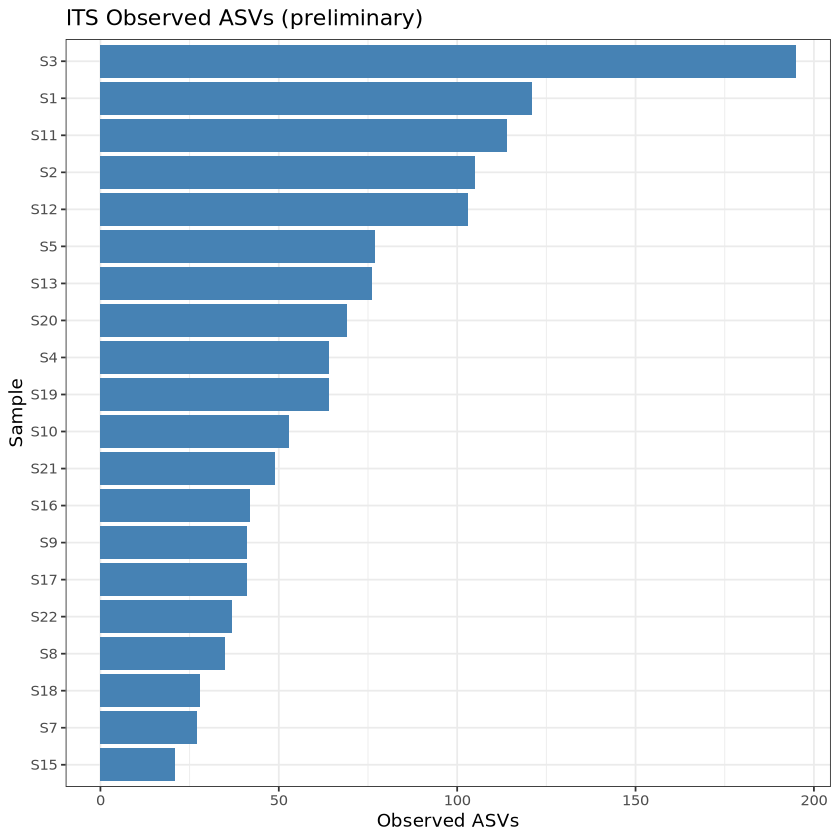

In [20]:
rel <- sweep(mat, 1, rowSums(mat), "/")
alpha <- data.frame(sample_id=rownames(mat), reads=rowSums(mat),
  Observed=rowSums(mat>0), Shannon=vegan::diversity(mat, "shannon"),
  Simpson=vegan::diversity(mat, "simpson"))
alpha$Pielou <- ifelse(alpha$Observed>1,
  alpha$Shannon/log(alpha$Observed), NA_real_)
for (field in intersect(c("site_type", "sampling_date", "altitude_min_m",
                          "altitude_max_m", "air_volume_m3", "dna_yield_ng_m3"), names(meta_for_ps)))
  alpha[[field]] <- meta_for_ps[match(alpha$sample_id, meta_for_ps$sample_id), field]



print(alpha)
p_alpha <- ggplot2::ggplot(alpha, ggplot2::aes(x=reorder(sample_id, Observed), y=Observed)) +
  ggplot2::geom_col(fill="steelblue") + ggplot2::coord_flip() +
  ggplot2::theme_bw() + ggplot2::labs(title=paste(marker, "Observed ASVs (preliminary)"),
                                    x="Sample", y="Observed ASVs")
print(p_alpha)


## 16. Диагностика глубины секвенирования

Кривые rarefaction выводятся в итоговый многостраничный PDF. Основные ASV-счётчики не рарефицируются.


In [21]:
if (nrow(mat)>=2L && ncol(mat)>=2L) {
  cat("Rarefaction diagnostic will be included in ITS_figures.pdf.\n")
  cat("Minimum library depth:",min(rowSums(mat)),"\n")
}


Rarefaction diagnostic will be included in ITS_figures.pdf.
Minimum library depth: 34687 


## 17. Относительная численность родов

Относительные численности и визуализация строятся по **итоговому столбцу `Genus`** с учётом предварительно уточнённых BLAST-родов (такие назначения отмечены в общей таксономической таблице). Видовые определения берутся только из согласованных RDP × BLASTN.


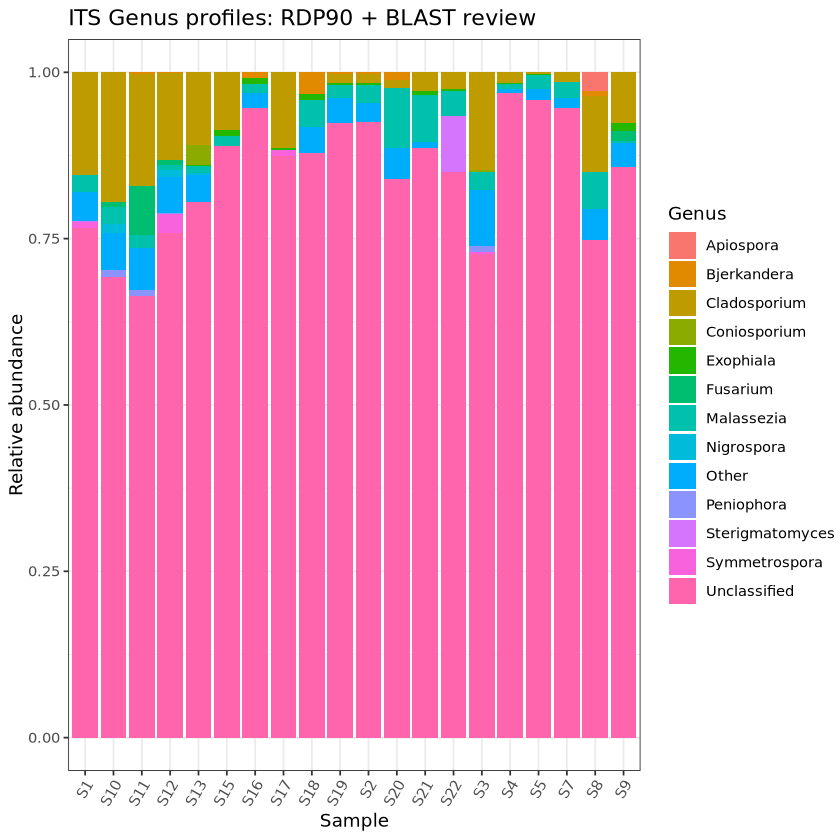

In [22]:
if (!"Genus" %in% colnames(tax_target)) stop("No Genus rank in taxonomy")
genus <- sub("^g__", "", as.character(tax_target[colnames(rel), "Genus"]))
genus[is.na(genus) | !nzchar(genus)] <- "Unclassified"
genus_rel <- t(rowsum(t(rel), group=genus, reorder=TRUE))

leaders <- head(names(sort(colMeans(genus_rel), decreasing=TRUE)), 12L)
plot_tab <- genus_rel[, leaders, drop=FALSE]
if (ncol(plot_tab)<ncol(genus_rel)) plot_tab <- cbind(plot_tab, Other=pmax(0, 1-rowSums(plot_tab)))
plot_df <- as.data.frame(as.table(plot_tab), stringsAsFactors=FALSE)
names(plot_df) <- c("Sample", "Genus", "Relative_abundance")
plot_df$Sample <- factor(plot_df$Sample, levels=rownames(genus_rel))
p_genus <- ggplot2::ggplot(plot_df, ggplot2::aes(Sample, Relative_abundance, fill=Genus)) +
  ggplot2::geom_col() + ggplot2::theme_bw() +
  ggplot2::theme(axis.text.x=ggplot2::element_text(angle=60, hjust=1)) +
  ggplot2::labs(title=paste(marker, "Genus profiles: RDP90 + BLAST review"),
                x="Sample", y="Relative abundance")
print(p_genus)


## 18. Бета-разнообразие, PCoA, PERMANOVA

Bray–Curtis рассчитывается по относительным ASV-счётчикам, Jaccard — по присутствию/отсутствию. При достаточном числе образцов выполняются PERMANOVA и проверка неоднородности дисперсий между Flight/Ground.


              test       comparison statistic_F         R2   p_value
1        PERMANOVA Flight vs Ground   0.7942884 0.04226222 0.6250000
2 betadisper_ANOVA Flight vs Ground   1.9317280         NA 0.1815209


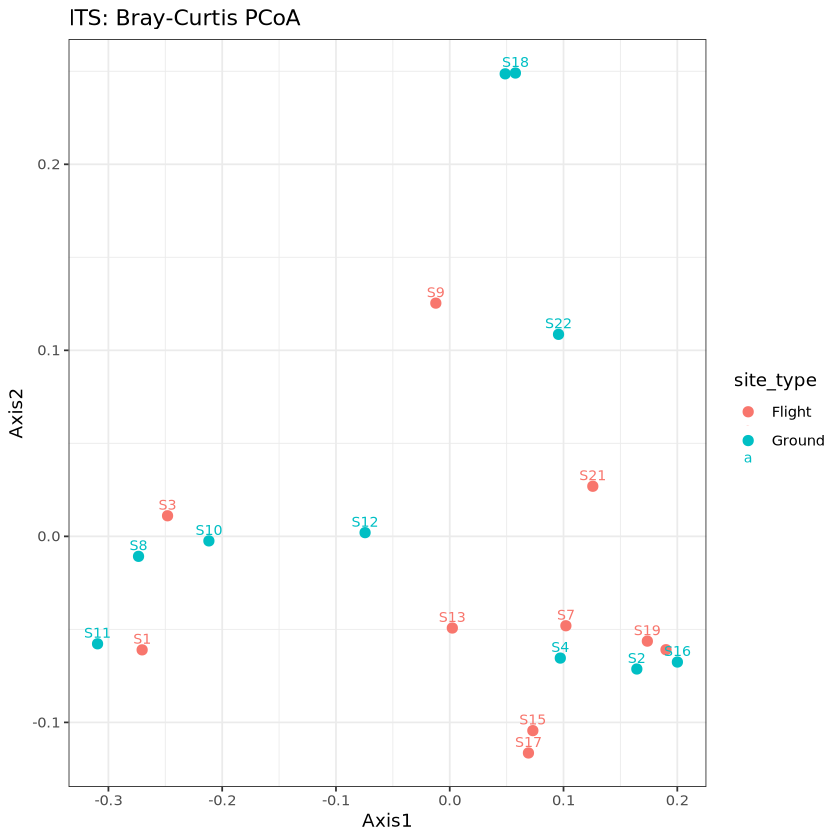

In [23]:
beta_tests <- NULL
p_pcoa <- NULL
pcoa_df <- NULL
if (nrow(mat)>=3L && ncol(mat)>=2L) {
  bray <- vegan::vegdist(rel, method="bray")
  jaccard <- vegan::vegdist(mat>0, method="jaccard", binary=TRUE)
  pcoa <- stats::cmdscale(bray, k=2, eig=TRUE, add=TRUE)
  pcoa_df <- data.frame(sample_id=rownames(pcoa$points),
                        Axis1=pcoa$points[,1], Axis2=pcoa$points[,2])
  for (field in intersect(c("site_type","sampling_date"),names(meta_for_ps))) {
    pcoa_df[[field]] <- meta_for_ps[match(pcoa_df$sample_id,meta_for_ps$sample_id),field]
  }
  p_pcoa <- if ("site_type" %in% names(pcoa_df))
    ggplot2::ggplot(pcoa_df, ggplot2::aes(Axis1, Axis2, color=site_type, label=sample_id))
  else ggplot2::ggplot(pcoa_df, ggplot2::aes(Axis1, Axis2, label=sample_id))
  p_pcoa <- p_pcoa + ggplot2::geom_point(size=2.5) +
    ggplot2::geom_text(vjust=-0.6,check_overlap=TRUE,size=3) +
    ggplot2::theme_bw() +
    ggplot2::labs(title="ITS: Bray-Curtis PCoA")
  print(p_pcoa)

  if ("site_type" %in% names(meta_for_ps)) {
    group <- factor(meta_for_ps[rownames(mat),"site_type"])
    if (all(!is.na(group)) && nlevels(group)==2L && all(table(group)>=2L)) {
      perm_data <- data.frame(site_type=group,row.names=rownames(mat))
      perm <- vegan::adonis2(bray ~ site_type,data=perm_data,permutations=999)
      disp <- vegan::betadisper(bray,group)
      disp_test <- stats::anova(disp)
      beta_tests <- data.frame(
        test=c("PERMANOVA", "betadisper_ANOVA"),
        comparison="Flight vs Ground",
        statistic_F=c(as.numeric(perm[1,"F"]), as.numeric(disp_test[1,"F value"])),
        R2=c(as.numeric(perm[1,"R2"]),NA_real_),
        p_value=c(as.numeric(perm[1,"Pr(>F)"]),as.numeric(disp_test[1,"Pr(>F)"]))
      )
      print(beta_tests)
    } else cat("Insufficient group replication for PERMANOVA.\n")
  }
} else cat("Not enough samples or taxa for beta diversity.\n")


## 19. Погода и экстремальные явления (только при реальных измерениях)

Если в исходных метаданных нет погоды, тесты **пропускаются**. Корреляция со Shannon — разведочный анализ, который не доказывает причинную связь. Для полноценной работы с экстремальными явлениями потребуются проверенные пороги, даты и лаги.


In [24]:
weather_columns <- c("temp_c","rh_pct","wind_ms","precip_mm",
                     "pressure_hpa","pm25","pm10")
weather_rows <- list()
for (field in intersect(weather_columns,names(meta_for_ps))) {
  x <- suppressWarnings(as.numeric(meta_for_ps[alpha$sample_id,field]))
  y <- alpha$Shannon
  ok <- is.finite(x) & is.finite(y)
  if (sum(ok)>=8L && length(unique(x[ok]))>=3L) {
    test <- suppressWarnings(stats::cor.test(x[ok],y[ok],method="spearman",exact=FALSE))
    weather_rows[[field]] <- data.frame(variable=field,n=sum(ok),
      rho=unname(test$estimate),p_value=test$p.value)
  }
}
weather_associations <- if (length(weather_rows)) do.call(rbind,weather_rows) else NULL
if (!is.null(weather_associations)) {
  weather_associations$p_BH <- p.adjust(weather_associations$p_value,"BH")
  print(weather_associations)
} else cat("No verified weather measurements suitable for statistical testing.\n")
if ("extreme_event" %in% names(meta_for_ps)) {
  event <- as.character(meta_for_ps[alpha$sample_id,"extreme_event"])
  event[event %in% c("1","TRUE","true","T")] <- "TRUE"
  event[event %in% c("0","FALSE","false","F")] <- "FALSE"
  valid <- !is.na(event) & event %in% c("TRUE","FALSE")
  if (sum(valid)>0L) {
    print(aggregate(alpha$Shannon[valid], list(extreme_event=event[valid]),
                    function(x)c(n=length(x),mean=mean(x),median=median(x))))
  }
}


No verified weather measurements suitable for statistical testing.


## 20. Итоговые результаты ITS

Все итоговые файлы записываются непосредственно в **`results/ITS/`**, которая создаётся при запуске. Временный подкаталог `results/ITS/.work/` удаляется после успешного завершения:

- `ITS_taxonomy_complete.tsv` — **единая таблица для всех ASV:** последовательность, итоговая таксономия, таксоны и bootstrap RDP, BLAST-попадания, обоснование видового согласования и флаги неопределённости.
- `ITS_ASV_counts.tsv`, `ITS_sample_metadata.tsv`, `ITS_phyloseq.rds` — входы для дальнейшей статистики по грибным ASV.
- `ITS_read_tracking.tsv`, `ITS_alpha_diversity.tsv`, `ITS_genus_relative_abundance.tsv` — качество, разнообразие и профили родов.
- `ITS_PCoA.tsv`, `ITS_beta_tests.tsv` и `ITS_weather_associations.tsv` — создаются только когда анализ допустим по имеющимся данным.
- `ITS_figures.pdf` — единый PDF с графиками, `ITS_MultiQC.html` — единый отчёт качества (если включён FastQC), `ITS_run_info.txt` — параметры и версии ПО.

Промежуточные FASTQ, BLAST-база, полная выгрузка попаданий и логи находятся в `results/ITS/.work/`. **После успешного завершения** этот временный подкаталог удаляется. При ошибке он остаётся для диагностики; папка `results/ITS/` в таком случае не считается готовым результатом, и для запуска с нуля её следует предварительно удалить.


In [25]:
# Экспортируем только итоговые файлы непосредственно в results/ITS/.
write_rows(tax_complete,"ITS_taxonomy_complete.tsv")
write_matrix(mat,"ITS_ASV_counts.tsv")
write_rows(meta_for_ps,"ITS_sample_metadata.tsv")
saveRDS(ps,file.path(outdir,"ITS_phyloseq.rds"))
write_rows(track,"ITS_read_tracking.tsv")
write_rows(alpha,"ITS_alpha_diversity.tsv")
write_matrix(genus_rel,"ITS_genus_relative_abundance.tsv")
if (!is.null(pcoa_df)) write_rows(pcoa_df,"ITS_PCoA.tsv")
if (!is.null(beta_tests)) write_rows(beta_tests,"ITS_beta_tests.tsv")
if (!is.null(weather_associations))
  write_rows(weather_associations,"ITS_weather_associations.tsv")

# All plots into a single PDF rather than many PNG files.
pdf_file <- file.path(outdir,"ITS_figures.pdf")
grDevices::pdf(pdf_file,width=11,height=7,onefile=TRUE)
print(p_alpha)
print(p_genus)
if (!is.null(p_pcoa)) print(p_pcoa)
if (nrow(mat)>=2L && ncol(mat)>=2L) {
  vegan::rarecurve(mat,step=max(1L,floor(min(rowSums(mat))/25)),
    sample=min(rowSums(mat)),label=FALSE,
    xlab="Sequenced reads",ylab="Observed fungal ASVs",
    main="ITS rarefaction (diagnostic)")
}
grDevices::dev.off()

if (run_fastqc) {
  multiqc_src <- file.path(workdir,"multiqc","multiqc_report.html")
  if (!file.exists(multiqc_src) ||
      !file.copy(multiqc_src,file.path(outdir,"ITS_MultiQC.html"),overwrite=TRUE))
    stop("Could not copy final MultiQC HTML")
}

cmd_version <- function(cmd,arg="-version") {
  x <- tryCatch(system2(Sys.which(cmd),arg,stdout=TRUE,stderr=TRUE),
                error=function(e) paste("unavailable",conditionMessage(e)))
  paste(head(x,2),collapse=" ")
}
info <- c(
  "ITS integrated processing (RDP90 + UNITE BLASTN)",
  paste("Date:",as.character(Sys.time())),
  paste("Reference:",taxonomy_ref),
  paste("Reference MD5:",unname(tools::md5sum(taxonomy_ref))),
  paste("Samples:",nrow(mat)),
  paste("Nonchimeric ITS ASVs:",nrow(tax_complete)),
  paste("Fungal ASVs RDP90:",ncol(mat)),
  paste("Fungal reads:",sum(mat)),
  paste("Confirmed species ASVs (all ASVs):",sum(confirmed)),
  paste("Provisional BLAST-only genus ASVs:",sum(rescue_genus)),
  paste("Genus conflicts:",sum(genus_conflict)),
  paste("RDP minBoot:",min_boot),
  paste("BLAST identity threshold:",blast_min_identity),
  paste("BLAST coverage threshold:",blast_min_coverage),
  paste("BLAST E-value threshold:",blast_max_evalue),
  paste("BLAST max hits:",blast_max_hits),
  paste("BLAST near-best bitscore window:",blast_near_best_bits),
  paste("SLURM node:",Sys.info()[["nodename"]]),
  paste("Threads:",threads),
  paste("R version:",R.version.string),
  paste("DADA2 version:",as.character(utils::packageVersion("dada2"))),
  paste("phyloseq version:",as.character(utils::packageVersion("phyloseq"))),
  paste("vegan version:",as.character(utils::packageVersion("vegan"))),
  paste("blastn version:",cmd_version("blastn")),
  paste("makeblastdb version:",cmd_version("makeblastdb")),
  paste("cutadapt version:",cmd_version("cutadapt","--version")),
  "Important: BLAST uses same UNITE reference as RDP; no independent reference validation.",
  "Important: species requires RDP90 and BLASTN species name agreement.",
  "Important: genus BLAST-only rescue is marked provisional, not confirmed.",
  "Important: no decontam without verified negative controls; no meteorology inferred."
)
writeLines(info,file.path(outdir,"ITS_run_info.txt"))

# Проверяем итоговый набор и только затем удаляем временные файлы.
necessary <- c("ITS_taxonomy_complete.tsv","ITS_ASV_counts.tsv",
  "ITS_phyloseq.rds","ITS_read_tracking.tsv","ITS_alpha_diversity.tsv",
  "ITS_genus_relative_abundance.tsv","ITS_figures.pdf","ITS_run_info.txt")
if (!all(file.exists(file.path(outdir,necessary)))) {
  stop("Не все итоговые файлы созданы. Технические файлы сохранены в: ", workdir)
}
if (!all(file.info(file.path(outdir,necessary))$size > 0L)) {
  stop("Некоторые итоговые файлы пусты. Технические файлы сохранены в: ", workdir)
}
unlink(workdir, recursive=TRUE)
if (dir.exists(workdir)) {
  warning("Временные файлы не удалились автоматически: ", workdir)
}

cat("\nITS ANALYSIS COMPLETED.\n",
    "Fungal reads:",sum(mat),"| fungal ASVs:",ncol(mat),
    "| species consensus ASVs:",sum(confirmed),"\n",
    "Final output:",outdir,"\n",
    "Files:",paste(list.files(outdir),collapse=", "),"\n")


pdf 
  2


ITS ANALYSIS COMPLETED.
 Fungal reads: 1620250 | fungal ASVs: 820 | species consensus ASVs: 0 
 Final output: /home/panishevasa/airlab/pipeline/results/ITS 
 Files: ITS_alpha_diversity.tsv, ITS_ASV_counts.tsv, ITS_beta_tests.tsv, ITS_figures.pdf, ITS_genus_relative_abundance.tsv, ITS_MultiQC.html, ITS_PCoA.tsv, ITS_phyloseq.rds, ITS_read_tracking.tsv, ITS_run_info.txt, ITS_sample_metadata.tsv, ITS_taxonomy_complete.tsv 
